In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt

### Data Cleaning & Initial Validation

In [2]:
df = pd.read_csv("paysim.csv")

In [3]:
df.shape

(6362620, 11)

In [4]:
df.duplicated().sum()

np.int64(0)

In [5]:
df.isnull().sum()

step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

In [6]:
numeric_cols = df.select_dtypes(include='number').columns
print("\n Infinite Values: ", df[numeric_cols].isin([float('inf'), float("-inf")]).sum())


 Infinite Values:  step              0
amount            0
oldbalanceOrg     0
newbalanceOrig    0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64


In [7]:
print("\n Target Distribution : ", df["isFraud"].value_counts())


 Target Distribution :  isFraud
0    6354407
1       8213
Name: count, dtype: int64


###  Conclusion :
    - No missig values found
    - No duplicate values
    - No infinite values
- Distribution:
  - We got 6,362,620 rows intact
  - 8213 fruad count

In [8]:
# Temporal analysis
#     Fraud by step
#     Fraud rate over time
#     Fraud transaction volume over time
#     Peak fraud periods

In [9]:
temporal_EDA = (
    df.groupby("step").agg(
        total_transactions=("isFraud", "size"),
        fraud_transactions=("isFraud", "sum")
    )
)
temporal_EDA["fraud_rate"] = (
    temporal_EDA["fraud_transactions"] / 
    temporal_EDA["total_transactions"]
    * 100
)

print("step range:", df["step"].min(), "to", df["step"].max())
print("\n Highest_Fraud_transactions_counts ",
    temporal_EDA
    .sort_values("fraud_transactions", ascending=False).head(10)
)

step range: 1 to 743

 Highest_Fraud_transactions_counts        total_transactions  fraud_transactions  fraud_rate
step                                                    
212                34047                  40    0.117485
523                   30                  30  100.000000
387                   28                  28  100.000000
501                   28                  28  100.000000
730                   28                  28  100.000000
425                   28                  28  100.000000
249                23209                  28    0.120643
398                26656                  26    0.097539
160                27765                  26    0.093643
406                12023                  24    0.199617


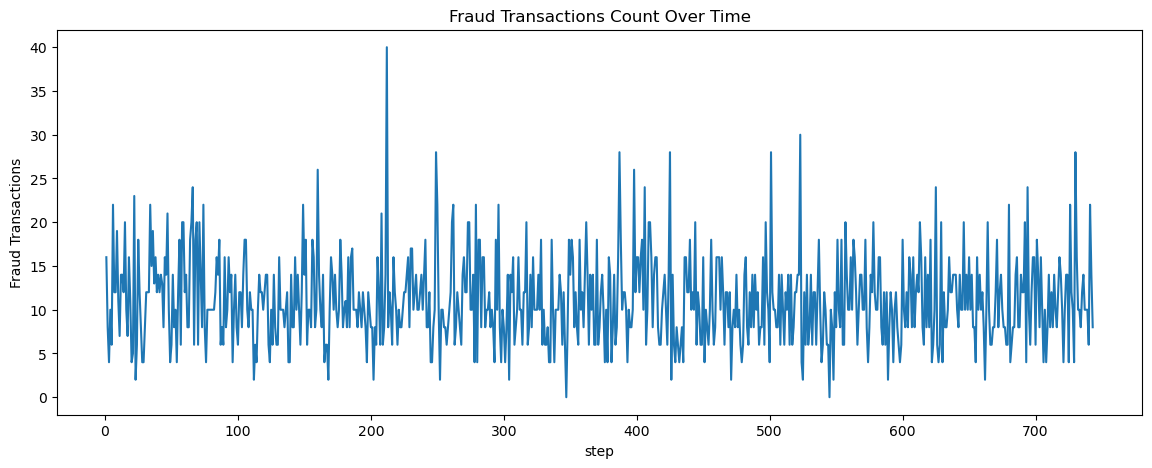

In [10]:
plt.figure(figsize=(14,5))
plt.plot(
    temporal_EDA.index,
    temporal_EDA["fraud_transactions"]
)
plt.xlabel("step")
plt.ylabel("Fraud Transactions")
plt.title("Fraud Transactions Count Over Time")
plt.show()

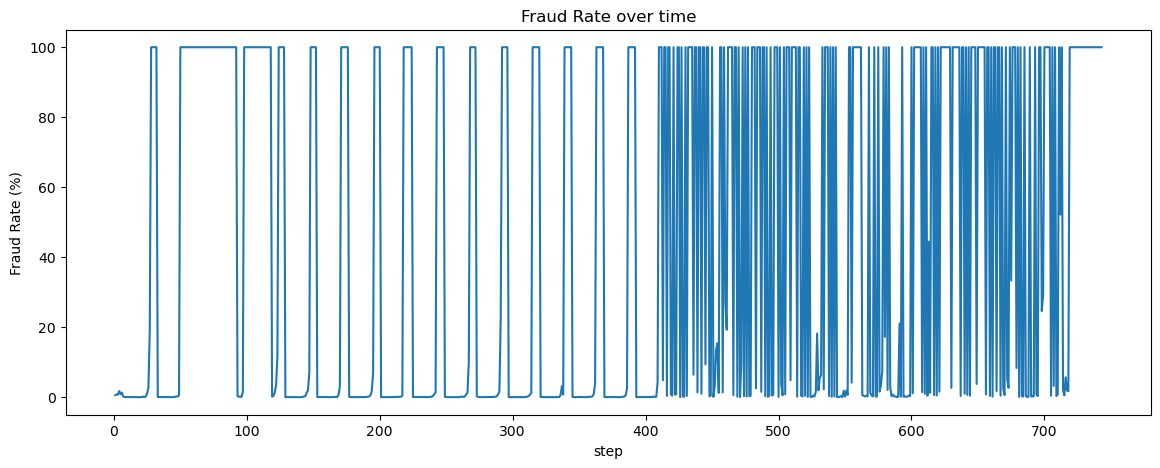

In [11]:
plt.figure(figsize=(14,5))
plt.plot(
    temporal_EDA.index,
    temporal_EDA["fraud_rate"]
)
plt.xlabel("step")
plt.ylabel("Fraud Rate (%)")
plt.title("Fraud Rate over time")
plt.show()

### Conclusion:
    - step ranges : 1 to 743 
    - roughly 31 days of hourly transaction steps.
    - we can see the 100 % fraud rate at steps 523, 387, 501, 730, 425 (But this can be misleading because there only 28 to 30 transactions present on those steps )
    - at step 212 there are 34047 trx and 40 fraud  and fraud rate  ~ 0.117 % 
    - therefore It is import to check the fraud count + fraud rate + transaction vol altogethe
- In plotting:
    - we got 100% fraud rate which does not means it is high risk period.
    - if denomemator has 28 trx then rate misleading could be huge

-Note: 
    - Fraud rate should be interpreted together with transaction volume,
    because rates based on very few transactions can be statistically unstable.

In [12]:
# Transaction-type analysis
    # Transaction volume by type
    # Fraud count by type
    # Fraud rate within each type ← important distinction

In [13]:
df.columns.tolist()

['step',
 'type',
 'amount',
 'nameOrig',
 'oldbalanceOrg',
 'newbalanceOrig',
 'nameDest',
 'oldbalanceDest',
 'newbalanceDest',
 'isFraud',
 'isFlaggedFraud']

In [14]:
type_eda = (
    df.groupby("type").agg(
        total_transactions=("isFraud", "size"),
        fraud_transactions=("isFraud", "sum")
    )
)

type_eda["Non_Fraud_transactions"] = (
    type_eda["total_transactions"] - type_eda["fraud_transactions"]
)

type_eda["Fraud_rate_percentage"] =  (
    type_eda["fraud_transactions"] / type_eda["total_transactions"] * 100
)

type_eda["Fraud_share_percent"] = (
    type_eda["fraud_transactions"] / df["isFraud"].sum()  * 100
)

type_eda = type_eda.sort_values(
    "Fraud_rate_percentage",
    ascending = False
)
print(type_eda)
print("\n Fraud rate by transaction type: ")
for transaction_type, row in type_eda.iterrows():
    print(
        f"{transaction_type}:"
        f"{row['Fraud_rate_percentage']:.6f} %"
    )

          total_transactions  fraud_transactions  Non_Fraud_transactions  \
type                                                                       
TRANSFER              532909                4097                  528812   
CASH_OUT             2237500                4116                 2233384   
CASH_IN              1399284                   0                 1399284   
DEBIT                  41432                   0                   41432   
PAYMENT              2151495                   0                 2151495   

          Fraud_rate_percentage  Fraud_share_percent  
type                                                  
TRANSFER               0.768799             49.88433  
CASH_OUT               0.183955             50.11567  
CASH_IN                0.000000              0.00000  
DEBIT                  0.000000              0.00000  
PAYMENT                0.000000              0.00000  

 Fraud rate by transaction type: 
TRANSFER:0.768799 %
CASH_OUT:0.183955 %
CASH_IN

### Conclusion
    - Most fraud happens in TRANSFER and CASH_OUT transactions
    - Both have almost the same number of fraud cases,
    - but TRANSFER has a higher fraud rate because there are fewer TRANSFER transactions overall.

- In simpl term :
  - “Fraud is mainly found in TRANSFER and CASH_OUT.
  - TRANSFER has a higher fraud percentage,
  - while both contribute almost equally to the total fraud cases.”

In [15]:
# Amount analysis
#     Fraud vs non-fraud amount
#     Distribution
#     Median / percentiles
#     Extreme transactions

In [16]:
amount_eda = (
    df.groupby("isFraud")["amount"]
    .agg(
        count = "count",
        mean = "mean",
        median = "median",
        std = "std",
        min = "min",
        q25 = lambda x: x.quantile(0.25),
        q75 = lambda x: x.quantile(0.75),
        max = "max"
    )
)

print("======== Aount Distribution : fraud vs non Fraud : ===== " )
print(amount_eda)

======== Aount Distribution : fraud vs non Fraud : ===== 
           count          mean     median           std   min         q25  \
isFraud                                                                     
0        6354407  1.781970e+05   74684.72  5.962370e+05  0.01   13368.395   
1           8213  1.467967e+06  441423.44  2.404253e+06  0.00  127091.330   

                q75          max  
isFraud                           
0         208364.76  92445516.64  
1        1517771.48  10000000.00  


In [17]:
print("\n ======== Fraud / Non Fraud Median Ratio ===========")
fraud_median = df.loc[df["isFraud"] == 1, "amount"].median()
nonfraud_median = df.loc[df["isFraud"] == 0, "amount"].median()

print("Fraud median: ", fraud_median)
print("Non-fraud median:", nonfraud_median)
print("Median ratio: ", fraud_median / nonfraud_median)


 ======== Fraud / Non Fraud Median Ratio ===========
Fraud median:  441423.44
Non-fraud median: 74684.72
Median ratio:  5.910491998898838


### Conlusion: 
    - Fraud transactions generally involve much larger amounts than normal transactions.
    - The median fraud transaction amount is about 5.9 times higher than the median non-fraud transaction

- Note:
  - It does not mean that every large transaction is Fraud.
  - amount is an useful feature but cannot prove fraud alone 

In [18]:
# Amount by Transaction Type
    # we will check the amount behaviour 
    # of fraud transaction in Transaction and cashout

In [19]:
amount_type_eda = (
    df.groupby(["type","isFraud"])["amount"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        q25 = lambda x: x.quantile(0.25),
        q75 = lambda x: x.quantile(0.75),
        max = "max"
    )
)

print("=========== AMOUNT BY TRANSACTION TYPE & FRAUD STATUS ==========")
print(amount_type_eda)

=========== AMOUNT BY TRANSACTION TYPE & FRAUD STATUS ==========
                    count          mean      median          q25  \
type     isFraud                                                   
CASH_IN  0        1399284  1.689202e+05  143427.710   70510.1825   
CASH_OUT 0        2233384  1.739172e+05  146946.560   72627.6900   
         1           4116  1.455103e+06  435516.905  125464.4500   
DEBIT    0          41432  5.483665e+03    3048.990    1500.1800   
PAYMENT  0        2151495  1.305760e+04    9482.190    4383.8200   
TRANSFER 0         528812  9.062290e+05  486521.910  216570.7650   
         1           4097  1.480892e+06  445705.760  128417.9600   

                           q75          max  
type     isFraud                             
CASH_IN  0        2.398991e+05   1915267.90  
CASH_OUT 0        2.461812e+05   2847566.62  
         1        1.500761e+06  10000000.00  
DEBIT    0        5.479175e+03    569077.51  
PAYMENT  0        1.756122e+04    238637.98  


### Conclusion: 
    - Fraudulent TRANSFER and CASH_OUT transactions generally have much higher amounts than their normal transactions.
    - This suggests transaction amount can be a useful fraud-detection feature.

- For Example:
   - CASH_OUT median: 146,946 → fraud median: 435,517
   - TRANSFER median: 486,522 → fraud median: 445,706

- Amount shows a strong difference for CASH_OUT fraud, while the pattern is less clear for TRANSFER

- Therefore, amount should be combined with other behavioural features rather than used alone

In [20]:
# Sender Balance Behaviour
    # we will investigate whether the sender's balance changed as expected after
    # a transaction took place.

In [21]:
df["origin_balance_erro"] = (
    df["oldbalanceOrg"]
    - df["amount"]
    - df["newbalanceOrig"]
)
df.groupby("isFraud")["origin_balance_erro"].agg(
    count = "count",
    mean = "mean",
    median = "median",
    std = "std",
    min ="min",
    max = "max"
)

df["abs_origin_balance_error"] = (
    df["origin_balance_erro"].abs()
)

df.groupby("isFraud")["abs_origin_balance_error"].agg(
    mean = "mean",
    median = "median",
    q75 = lambda x: x.quantile(0.75),
    max = "max"
)

,mean,median,q75,max
isFraud,,,,
0,201338.558304,69049.31,249953.43,92445516.64
1,10692.325265,0.00,0.00,10000000.00


### Conlcusion: 
    - For fraudulent transactions, the sender balance usually matches the expected balance change much more closely
    - while normal transactions show larger balance differences.
- Form Data we got : 
  - Fraud median error = 0
  - Fraud Q75 error = 0
  - Normal median error ~ 69,049
  - Normal Q75 ~ 249,953

- Important :
    - origin_balance_error = 0 does not prove that it is fraud.
    - It only shows the transaction generation pattern of dataset

In [22]:
# Receiver Balance Behaviour
    # same as sender behaviour for reciever 

In [23]:
df["destination_balance_error"] = (
    df["oldbalanceDest"]
    + df["amount"]
    - df["newbalanceDest"]
)

df.groupby("isFraud")["destination_balance_error"].agg(
        count = "count",
        mean = "mean",
        median = "median",
        std = "std",
        min = "min",
        q25 = lambda x: x.quantile(0.25),
        q75 = lambda x: x.quantile(0.75),
        max = "max"
    
    )

df["abs_destination_balance_error"] = (
    df["destination_balance_error"].abs()
)

df.groupby("isFraud")["abs_destination_balance_error"].agg(
      mean="mean",
      median="median",
      q75=lambda x: x.quantile(0.75),
      max="max"
    )

,mean,median,q75,max
isFraud,,,,
0,92756.964361,5123.10,43227.16,75885725.63
1,745138.585637,9511.69,452294.74,10000000.00


### conclusion
    - The receiver balance follows the expected balance change exactly for both fraud and non-fraud transactions
    - so this feature does not help distinguish fraud in this dataset.

- Normal → error 0
- Fraud → error 0
- So destination_balance_error doesn't separate the classes.

In [24]:
# Sender Balance vs Transaction Amount
    # Here we will check : 
        # What proportion of the sender's total account balance is actually
        # being withdrawn during a fraudulent transaction?

In [25]:
df["amount_to_origin_ratio"] = np.where(
    df["oldbalanceOrg"] > 0,
    df["amount"] / df["oldbalanceOrg"],
    np.nan
)

ratio_eda = (
    df.groupby("isFraud")["amount_to_origin_ratio"].agg(
        count="count",
        mean="mean",
        median="median",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75),
        max="max"
    )
)
print("======= Amount / Origin_Balance_Ratio")
print(ratio_eda)

======= Amount / Origin_Balance_Ratio
           count        mean    median      q25       q75           max
isFraud                                                                
0        4251999  122.272735  0.734717  0.07426  6.684667  3.925476e+06
1           8172    0.998765  1.000000  1.00000  1.000000  2.952662e+01


In [26]:
print("======== Fraud Transactions with Ratio >= 1")
fraud_ratio = df.loc[
    df["isFraud"] == 1,
    "amount_to_origin_ratio"
]
print(
    (fraud_ratio >= 1).sum(),
    "out of ",
    len(fraud_ratio)
)

print(
    "Percentage:",
    (fraud_ratio >= 1).mean() * 100, "%"
)

======== Fraud Transactions with Ratio >= 1
8022 out of  8213
Percentage: 97.67441860465115 %


### Coclusion: 
    -Almost all fraud transactions (97.67%) have an amount equal 
        to or greater than the sender's old balance
    -For normal transactions, this ratio is much more variable.

- From Data: 
    - Fraud: 8,022 / 8,213 = 97.67%
    - Fraud median ratio = 1.0
    - Normal median ratio = 0.735
- This data is showing potentially very strong fraud signal

- But there is something: 
    - In normal transaction max ratio is max = 3.9 million
    - Because:
        - Some transaction has oldbalanceOrg = 0 / very small.
        - Therefor mean = 122 is misleading.
            - median / qauntiles are more useful.

- Inshort: 
    - A strong pattern was observed in fraudulent transactions: 97.67% 
    - had transaction amounts greater than or equal to the sender's 
    - recorded opening balance

In [27]:
# Zero-Balance Behaviour
    # we will check how many fraud transactions are related to senderd zero balance?

In [28]:
zero_balance_eda = (
    df.groupby("isFraud").agg(
        total_transactions = ("isFraud", "size"),
        zero_origin_balance = (
            "oldbalanceOrg",
            lambda x: (x==0).sum()
        ),

        zero_new_origin_balance=(
            "newbalanceOrig",
            lambda x: (x==0).sum()
        ),

        zero_destination_balance=(
            "oldbalanceDest",
            lambda x: (x==0).sum()
        )
    )
)

zero_balance_eda["zero_origin_percent"] = (
    zero_balance_eda["zero_origin_balance"] / 
    zero_balance_eda["total_transactions"] * 100
)

zero_balance_eda["zero_new_origin_balance"] = (
    zero_balance_eda["zero_new_origin_balance"] /
    zero_balance_eda["total_transactions"] * 100
)

print(zero_balance_eda)

         total_transactions  zero_origin_balance  zero_new_origin_balance  \
isFraud                                                                     
0                   6354407              2102408                56.677405   
1                      8213                   41                98.051869   

         zero_destination_balance  zero_origin_percent  
isFraud                                                 
0                         2699037            33.085825  
1                            5351             0.499209  


### Conclusion: 
    - Normal transactions: Around 33.09% have oldbalanceOrg = 0.
    - Fraudulent transactions: Only about 0.50% have oldbalanceOrg = 0.
    - In fraud cases, 98.05% of transactions result in the sender’s new balance being zero.
    - In normal transactions, this “balance becomes zero” pattern is much less common.

- example: 
    - zero_new_origin_balance = 56.677405
        - It is impossible because counts cannot be fractional.
    - However, the key metric — zero_new_origin_percent = 98.05%.
        - for fraud — is clearly valid and highlights the strong pattern.

- Inshort: 
    - Fraudulent transactions show a strong behavioral pattern where the sender’s 
        - balance drops to zero after the transaction. 
    - This makes it a useful feature for fraud detection.

In [29]:
#  isFlaggedFraud vs isFraud (Existing Fraud Flag Analysis)
    #  IT is important Because Dataset has already given a fraud rule flag

In [30]:
flag_eda = (
    df.groupby(["isFraud", "isFlaggedFraud"])
    .size()
    .unstack(fill_value = 0)
)

print("\n==== isFlaggedFraud vs isFraud==== \n",flag_eda)


==== isFlaggedFraud vs isFraud==== 
 isFlaggedFraud        0   1
isFraud                    
0               6354407   0
1                  8197  16


In [31]:
fraud_total = (df["isFraud"] == 1).sum()
fraud_flagged = (
    (df["isFraud"] == 1) & 
    (df["isFlaggedFraud"] == 1)
).sum()

print("Total Fraud: ", fraud_total)
print("Fraud Flagged: ", fraud_flagged)
print("Fraud detection rate by existing flag: ", 
     fraud_flagged / fraud_total * 100, "%")

Total Fraud:  8213
Fraud Flagged:  16
Fraud detection rate by existing flag:  0.1948131011810544 %


### Conclusion: 
    - This result is very important beause existing isFlaggedFraud rule of dataset missing the almost fraud cases
    - Normal transaction :  flag = 0 -->  6354407  and    flag = 1 --->  0
    - Fraud transaction :   flag = 0  --> 8197     and    flag = 1 --->  16

            - total fraud cases: 8213
            - Fraud detected by existing flag: 16
            - Detectection rate: 0.195 %
            - Missed fraudd cased: 8197
            - False positived: 0(in this dataset)

- The existing isFlaggedFraud rule is extremely strict:
      - whenever it flagged a transaction, it was indeed fraud.
      - However, it missed almost all fraud cases — catching less than 1% of them.

- Note: 
    - Our ML model will not simply replicate this existing rule.
    - Instead, the goal is to combine transaction amount, balance behavior, transaction type, and other behavioral patterns to detect fraud risk more effectively
    - This approach ensures broader coverage and higher detection rates compared to the current flagging mechanism.
      

In [32]:
# Fraud Account Behaviour
    # We will check that which sender/receiver accoounts repeatedly involved in 
    # fraud trx.

In [33]:
fraud_df = df[df["isFraud"] == 1]

sender_fraud_counts = (
    fraud_df.groupby("nameOrig")
    .size()
    .sort_values(ascending=False)
)

receiver_fraud_counts = (
    fraud_df.groupby("nameDest")
    .size()
    .sort_values(ascending = False)
)
print("====== Top Fraud senders =============")
print(sender_fraud_counts.head(10))

====== Top Fraud senders =============
nameOrig
C1000036340    1
C334503836     1
C357089378     1
C356905617     1
C356781229     1
C356706674     1
C356571967     1
C356480504     1
C356205172     1
C356177155     1
dtype: int64


In [34]:
print("======== Top Fraud Receivers ==========")
print(receiver_fraud_counts.head(10))

======== Top Fraud Receivers ==========
nameDest
C2020337583    2
C650699445     2
C475338087     2
C505532836     2
C1185292292    2
C1399829166    2
C643624257     2
C967226405     2
C1366192319    2
C644163395     2
dtype: int64


In [35]:
print("\n ========== Unique Fraud Accounts =============== ")
print("Unique fraud seders:", fraud_df["nameOrig"].nunique())
print("Unique fraud receivers: ", fraud_df["nameDest"].nunique())


 ========== Unique Fraud Accounts =============== 
Unique fraud seders: 8213
Unique fraud receivers:  8169


### Conclusion : 
    - Fruad Senders Account Behavior:
        - Total fraud transactions: 8,213
        - Unique fraud senders: 8,213
        - This means almost every fraudulent transaction has a unique sender account.
        - Even the top fraud sender is involved in only 1 fraud transaction.

    - Fraud Receivers Account Behaviour:
        - Unique fraud receivers: 8,169
        - Against 8,213 fraud transactions, only 44 transactions show repetition.
        - A few receivers are involved in 2 fraud transactions each.

- Inshort:
  - Fraud sender accounts are mostly one-time accounts,
      - while a small number of receiver accounts are involved in multiple fraud transactions.
      - This finding is valuable for an investigation system,
      - because repeated fraud activity on the receiver side can serve as a strong investigation signal.

In [36]:
# Fraud Transaction Sequences
    # We’ll examine the transaction type and sequence patterns around 
    # fraudulent activity, 
    # with particular attention to the TRANSFER followed by CASH_OUT chain,
    # since this behavior often signals fraud.

In [37]:
fraud_transactions  = df[df["isFraud"] == 1].copy()

print("===== FRAUD TRANSACTION TYPES =====")
print(fraud_transactions["type"].value_counts())

===== FRAUD TRANSACTION TYPES =====
type
CASH_OUT    4116
TRANSFER    4097
Name: count, dtype: int64


In [38]:
print("\n===== FRAUD TYPE + STEP RANGE =====")
print(
    fraud_transactions
    .groupby("type")["step"]
    .agg(["count", "min", "max", "mean"])
)


===== FRAUD TYPE + STEP RANGE =====
          count  min  max        mean
type                                 
CASH_OUT   4116    1  743  367.720360
TRANSFER   4097    1  743  369.110569


In [39]:
print("\n ============ Fraud Transactions by step =============")
print(
    fraud_transactions
    .groupby("step")
    .size()
    .sort_values(ascending=False)
    .head(20)
)


 ============ Fraud Transactions by step =============
step
212    40
523    30
387    28
425    28
249    28
730    28
501    28
398    26
160    26
66     24
694    24
625    24
406    24
22     23
262    22
279    22
680    22
34     22
726    22
296    22
dtype: int64


### Conclusion: 
    - CASH_OUT frauds: 4,116
    - TRANSFER frauds: 4,097
    - Both contribute almost 50–50 to the total fraud count.
    - Fraud transactions are distributed across steps 1–743.
    - Average fraud step:
        - CASH_OUT ≈ 367.7
        - TRANSFER ≈ 369.1
- Note:
  - we’ve only looked at the distribution of fraud transactions. This alone does not prove the TRANSFER → CASH_OUT sequence.
  - To confirm the actual sequence, we need to connect sender/receiver accounts and analyze consecutive transactions.

- Note:
    - This deeper sequence analysis will be highly valuable for building an investigation engine
    - since it can uncover fraud chains and highlight suspicious account linkages
  

In [40]:
# Transfer → Cash-Out Relationship
    # We will specifically check whether a fraudulent TRANSFER’s receiver account 
    # later performs a CASH_OUT transaction.

In [41]:
fraud_transfer = df[
    (df["isFraud"] == 1) &
    (df["type"] == "TRANSFER")
][["step", "nameOrig", "nameDest", "amount"]]

fraud_cashout = df[
    (df["isFraud"] == 1) &
    (df["type"] == "CASH_OUT")
][["step", "nameOrig", "nameDest", "amount"]]

In [42]:
sequence_check = fraud_transfer.merge(
    fraud_cashout,
    left_on="nameDest",
    right_on="nameOrig",
    suffixes=("_transfer", "_cashout")
)

sequence_check = sequence_check[
    sequence_check["step_cashout"] > sequence_check["step_transfer"]
]

print("===== TRANSFER → CASH_OUT SEQUENCE =====")
print("Total matching sequences:", len(sequence_check))

===== TRANSFER → CASH_OUT SEQUENCE =====
Total matching sequences: 0


In [43]:
print("\nUnique accounts with sequence:",
      sequence_check["nameDest_transfer"].nunique())


Unique accounts with sequence: 0


In [44]:
print("\n===== SAMPLE =====")
print(sequence_check.head(10))


===== SAMPLE =====
Empty DataFrame
Columns: [step_transfer, nameOrig_transfer, nameDest_transfer, amount_transfer, step_cashout, nameOrig_cashout, nameDest_cashout, amount_cashout]
Index: []


In [45]:
fraud_transfer = df[
    (df["isFraud"] == 1) &
    (df["type"] == "TRANSFER")
][["step", "nameOrig", "nameDest", "amount"]]

fraud_cashout = df[
    (df["isFraud"] == 1) &
    (df["type"] == "CASH_OUT")
][["step", "nameOrig", "nameDest", "amount"]]

sequence_check = fraud_transfer.merge(
    fraud_cashout,
    left_on="nameDest",
    right_on="nameOrig",
    suffixes=("_transfer", "_cashout")
)

sequence_check = sequence_check[
    sequence_check["step_cashout"] > sequence_check["step_transfer"]
]

In [46]:
print("===== TRANSFER → CASH_OUT SEQUENCE =====")
print("Total matching sequences:", len(sequence_check))

print("\nUnique accounts with sequence:",
      sequence_check["nameDest_transfer"].nunique())

print("\n===== SAMPLE =====")
print(sequence_check.head(10))

===== TRANSFER → CASH_OUT SEQUENCE =====
Total matching sequences: 0

Unique accounts with sequence: 0

===== SAMPLE =====
Empty DataFrame
Columns: [step_transfer, nameOrig_transfer, nameDest_transfer, amount_transfer, step_cashout, nameOrig_cashout, nameDest_cashout, amount_cashout]
Index: []


### Conclusion:
 - We could not identify any direct TRANSFER → CASH_OUT chain among 
    the labelled fraud transactions using the available account and time fields
 - Under our strict sequence‑matching criteria, 
    no direct transfer‑to‑cash‑out chain was observed

In [47]:
# Balance depletion behaviour(Sender Balance Depletion)
    # since we have already seen strong pattern of newbalanceOrig = 0 .
    # we are going to quantify it cleanly.

In [48]:
depletion_eda = (
    df.groupby("isFraud").agg(
        total_transactions = ("isFraud", "size"),
        balance_drained = (
            "newbalanceOrig",
            lambda x: (x==0).sum()
        )
    )
)

depletion_eda["drained_percentage"] = (
    depletion_eda["balance_drained"] / 
    depletion_eda["total_transactions"] * 100
)

print("======= Sender Balance Depletion =============")
print(depletion_eda)

======= Sender Balance Depletion =============
         total_transactions  balance_drained  drained_percentage
isFraud                                                         
0                   6354407          3601513           56.677405
1                      8213             8053           98.051869


### Conclusion: 
    - Fraudulent transactions:
        - About 98.05% ended with the sender’s recorded balance at zero.

    - Normal transactions: 
        - About 56.68% ended with the sender’s balance at zero.

- Inshort:
        - Balance depletion was strongly associated with fraud in our dataset.
        - Around 98% of fraudulent transactions left the sender’s recorded balance at zero,
        - compared with around 57% of normal transactions.

- Note: 
    - Since more than half of normal transactions also show zero balance,
    - newbalanceOrig == 0 alone is not a reliable fraud detector.
    - However, when combined with other features — such as transaction type,
    - amount,and balance ratios — 
        - it becomes a useful engineered feature for fraud detection models.

In [49]:
# Numerical Feature Relationships
  # Goal: Identify which numerical columns are strongly correlated with each other.
  # Why: Helps detect redundancy, guides feature selection, 
  #      and prevents multicollinearity issues in machine learning models.
df.columns.tolist()

['step',
 'type',
 'amount',
 'nameOrig',
 'oldbalanceOrg',
 'newbalanceOrig',
 'nameDest',
 'oldbalanceDest',
 'newbalanceDest',
 'isFraud',
 'isFlaggedFraud',
 'origin_balance_erro',
 'abs_origin_balance_error',
 'destination_balance_error',
 'abs_destination_balance_error',
 'amount_to_origin_ratio']

In [50]:
numeric_cols = [
    "step",
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest",
    "isFlaggedFraud",
    "origin_balance_erro",
    "abs_origin_balance_error",
    "destination_balance_error",
    "abs_destination_balance_error",
    "amount_to_origin_ratio",
    "isFraud"
]

correlation_matrix = df[numeric_cols].corr()
print("\n========= Corrrelation with isFraud ==========",
      correlation_matrix["isFraud"]
      .sort_values(ascending=False)
)


========= Corrrelation with isFraud ========== isFraud                          1.000000
amount                           0.076688
destination_balance_error        0.055120
abs_destination_balance_error    0.053840
isFlaggedFraud                   0.044109
step                             0.031578
origin_balance_erro              0.011283
oldbalanceOrg                    0.010154
newbalanceDest                   0.000535
amount_to_origin_ratio          -0.001279
oldbalanceDest                  -0.005885
newbalanceOrig                  -0.008148
abs_origin_balance_error        -0.011283
Name: isFraud, dtype: float64


### Conclusion:
 - amount -> 0.0767 --> wealk positive correlation
 - step → 0.0316 → very weak
 - isFlaggedFraud → 0.0441 → weak overall correlation,
        - despite being highly precise when it does flag.
 - Balance variables → mostly near zero correlation.
     
====> Note: 
 - Low correlation does not mean a feature is useless. 
 - Fraud detection often involves nonlinear relationships

- Inshort:
  - Correlation analysis showed that no single numerical feature had a strong linear relationship with fraud.
  - Therefore, we relied on behavioral features and nonlinear ML models rather than selecting features purely based on correlation

In [51]:
# Outlier Analysis
    #  Compare the distribution of very large transaction amounts between
    # fraud and normal transactions

In [52]:
outlier_eda = (
    df.groupby("isFraud")["amount"]
    .quantile([0.25,0.50,0.75,0.95,0.99])
    .unstack()
)

outlier_eda.columns = [
    "Q1",
    "Median",
    "Q3",
    "95th_percentile",
    "99th_percentile"
]

print("\n ====== Amout Outlier analysis ========= ")
print(outlier_eda)
print("\n MAimum Amount: \n",df.groupby("isFraud")["amount"].max())


 ====== Amout Outlier analysis ========= 
                 Q1     Median          Q3  95th_percentile  99th_percentile
isFraud                                                                     
0         13368.395   74684.72   208364.76       515610.423     1.586064e+06
1        127091.330  441423.44  1517771.48      8006429.040     1.000000e+07

 MAimum Amount: 
 isFraud
0    92445516.64
1    10000000.00
Name: amount, dtype: float64


### Conclusion: 
    - Fraud transactions have much higher amount distribution.
    - Example:
        - Normal median ≈ 74.7K
        - Fraud median ≈ 441.4K
    - So fraud median is about 5.9× the normal median.
    - difference becomes even stronger at the upper percentiles
        - 95% of normal transactions are below ~515K
        - while the fraud 95th percentile is ~8.0M.

- Note: 
    - Fraudulent transactions tend to have substantially higher transaction amounts
    - but amount alone is not sufficient to identify fraud.

In [53]:
# Final EDA Summary(Feature Candidate Summary )
    # - systematically identify candidate features 
    #     - for the model based on our exploratory data analysis findings.

In [54]:
feature_candidates = {
    "KEEP_RAW_NUMERIC":[
        "step",
        "amount",
        "oldbalanceOrg",
        "newbalanceOrig",
        "oldbalanceDest",
        "newbalanceDest"
    ],

    "KEEP_EXISTING_FLAG":[
        "isFlaggedFraud"
    ],

    "DERIVE_BEHAVIOURAL_FEATURES":[
        "origin_balance_error",
        "abs_origin_balance_error",
        "amount_to_origin_ratio",
        "sender_balance_depleted",
        "destination_balance_depleted"
    ],

    "KEEP_CATEGORICAL":[
        "type"
    ],

    "INVESTIGATION_ONLY":[
        "nameOrig",
        "nameDest"
    ],

    "DROP_FROM_MODEL":[
        "isFraud",
        "destination_balance_error",
        "abs_destination_balance_error"
    ]
}

print("============ FINAL FEATURE CANDIDATES ===============")

for category, features in feature_candidates.items():
    print(f"{category}:")
    for feature in features:
        print("  -", feature)
    print()

============ FINAL FEATURE CANDIDATES ===============
KEEP_RAW_NUMERIC:
  - step
  - amount
  - oldbalanceOrg
  - newbalanceOrig
  - oldbalanceDest
  - newbalanceDest

KEEP_EXISTING_FLAG:
  - isFlaggedFraud

DERIVE_BEHAVIOURAL_FEATURES:
  - origin_balance_error
  - abs_origin_balance_error
  - amount_to_origin_ratio
  - sender_balance_depleted
  - destination_balance_depleted

KEEP_CATEGORICAL:
  - type

INVESTIGATION_ONLY:
  - nameOrig
  - nameDest

DROP_FROM_MODEL:
  - isFraud
  - destination_balance_error
  - abs_destination_balance_error



### Conclusion : 🧠 Final EDA Findings
- Fraud occurs mainly in TRANSFER and CASH_OUT transactions.
- Fraudulent transactions generally involve much higher amounts.
- In fraud cases, the sender’s balance becomes zero in about 98% of transactions
- The existing isFlaggedFraud feature detects only 16 out of 8,213 frauds.
- Fraud senders are mostly one‑time accounts
- A small number of receiver accounts are involved in multiple frauds
- No direct TRANSFER → CASH_OUT sequence was observed under strict criteria
- Simple numerical correlations were weak, highlighting the importance of nonlinear relationships
- Receiver balance error does not distinguish fraud from normal transactions